<a href="https://colab.research.google.com/github/jenish14433-sketch/nlp-course/blob/main/JENIS_Copy_of_lab3_2_word_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab3/lab3_2_word_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3.2 – Word and sentence embeddings

**Objectives**
- Train Word2Vec embeddings (CBOW and Skip-gram) on your own corpus
- Use pre-trained GloVe vectors and word analogies
- Compute sentence embeddings with a BERT-based model and use them for semantic search
- Compare lexical (TF-IDF) and semantic (embeddings) similarity

**Dataset:** the same 20 Newsgroups corpus and the same 3 categories as in Lab 3.1.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**.
3. This lab downloads pre-trained models (about 250 MB in total). Google Colab is recommended on a slow connection.

## Setup

In [ ]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt
!pip install -q gensim

In [ ]:
import os, re, string, urllib.request, warnings
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import gensim
from gensim.models import Word2Vec
import gensim.downloader as api
from sklearn.metrics.pairwise import cosine_similarity

print(f"gensim {gensim.__version__} – setup complete")

gensim 4.4.0 – setup complete


## Data (same as Lab 3.1)

In [ ]:
def local_file(name, lab="lab3"):
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))
df = df.dropna(subset=["text"]).reset_index(drop=True)

my_categories = [
    "sci.space",
    "rec.sport.hockey",
    "sci.electronics"
]  # YOUR CODE HERE: the same 3 categories as in Lab 3.1
assert len(set(my_categories)) == 3 and all(c in df["label_text"].unique() for c in my_categories), "Use 3 valid categories"

df_filtered = df[df["label_text"].isin(my_categories)].reset_index(drop=True)
print(f"{len(df_filtered)} documents in {my_categories}")

1784 documents in ['sci.space', 'rec.sport.hockey', 'sci.electronics']


In [ ]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_tokens(text):
    """Same cleaning as Lab 3.1, returning a list of tokens (Word2Vec expects tokenized sentences)."""
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [lemmatizer.lemmatize(t) for t in text.split() if t not in stop_words and len(t) >= 3]
    return tokens

df_filtered["tokens"] = df_filtered["text"].apply(preprocess_tokens)
df_filtered["text_clean"] = df_filtered["tokens"].apply(" ".join)
corpus = df_filtered["tokens"].tolist()
print(f"Corpus: {len(corpus)} documents, {sum(len(d) for d in corpus)} tokens")
print(corpus[0][:15])

Corpus: 1784 documents, 160857 tokens
['article', 'tom', 'baker', 'understanding', 'expected', 'error', 'basically', 'known', 'bug', 'warning', 'system', 'software', 'thing', 'checked', 'right']


---
# Part A – Word2Vec: train your own embeddings

Word2Vec learns a vector per word by predicting words from their context:
- **CBOW** predicts the target word from its context words,
- **Skip-gram** predicts the context words from the target word.

In [ ]:
common = dict(sentences=corpus, vector_size=100, window=5, min_count=5, workers=4, epochs=10, seed=42)
model_cbow = Word2Vec(sg=0, **common)
model_skipgram = Word2Vec(sg=1, **common)
print(f"Vocabulary size: {len(model_cbow.wv)} words")

Vocabulary size: 4953 words


In [ ]:
word = "hockey"   # change to a word of your domain
if word in model_cbow.wv:
    print(f"Vector of '{word}': shape {model_cbow.wv[word].shape}, first values {model_cbow.wv[word][:5]}")
    print("\nMost similar (CBOW):     ", [w for w, s in model_cbow.wv.most_similar(word, topn=8)])
    print("Most similar (Skip-gram):", [w for w, s in model_skipgram.wv.most_similar(word, topn=8)])
else:
    print(f"'{word}' is not in the vocabulary. Examples:", list(model_cbow.wv.key_to_index)[:20])

Vector of 'hockey': shape (100,), first values [ 0.52537197  0.17101261 -0.7433257  -0.3534489  -0.6173007 ]

Most similar (CBOW):      ['league', 'nhl', 'team', 'american', 'sport', 'european', 'regular', 'next']
Most similar (Skip-gram): ['sport', 'league', 'attended', 'basketball', 'college', 'nhl', 'roster', 'football']


### Exercise A.1 – CBOW vs Skip-gram

Choose **5 domain-specific words** of your categories (not generic words such as *good* or *make*) and compare the 5 most similar words given by each model.

In [ ]:
my_test_words = [
    "space",
    "nasa",
    "hockey",
    "game",
    "circuit"
]

for word in my_test_words:
    word = word.lower()
    if word in model_cbow.wv:
        print(f"\n'{word}'")
        print("  CBOW:     ", [w for w, s in model_cbow.wv.most_similar(word, topn=5)])
        print("  Skip-gram:", [w for w, s in model_skipgram.wv.most_similar(word, topn=5)])
    else:
        print(f"\n'{word}' not in vocabulary")

assert sum(w.lower() in model_cbow.wv for w in my_test_words) >= 3, "At least 3 of your words must be in the vocabulary"



'space'
  CBOW:      ['sci', 'nasa', 'archive', 'station', 'international']
  Skip-gram: ['edition', 'administration', 'jsc', 'activist', 'aerospace']

'nasa'
  CBOW:      ['ames', 'space', 'science', 'faq', 'archive']
  Skip-gram: ['gov', 'dryden', 'ames', 'jsc', 'msfc']

'hockey'
  CBOW:      ['league', 'nhl', 'team', 'american', 'sport']
  Skip-gram: ['sport', 'league', 'attended', 'basketball', 'college']

'game'
  CBOW:      ['played', 'playoff', 'pick', 'season', 'night']
  Skip-gram: ['played', 'playoff', 'streak', 'victory', 'televised']

'circuit'
  CBOW:      ['run', 'current', 'voltage', 'amp', 'input']
  Skip-gram: ['fuse', 'cord', 'device', 'impedance', 'extension']


### Question A.2 (written)

1. For which words do both models agree? For which do they differ?
2. Which model gives the better neighbours for your domain? Give examples.
3. Why can one architecture work better than the other for rare words? (think about how many training examples each word gets)

<!-- ANSWER lab3.2-A2 -->
1 Both CBOW and Skip-gram find similar neighbours for some words, especially common words such as "space", "hockey" and "game". However, they also differ in the words they suggest because they learn word relationships in different ways

2 In my experiments, Skip-gram generally provides more specific and meaningful neighbours for domain-related words such as "nasa", "hockey" and "circuit". CBOW sometimes gives more general neighbours.

3 Skip-gram can work better for rare words because it predicts surrounding context words from the target word. This helps it learn detailed relationships even when a word appears less frequently. CBOW predicts a target word from its surrounding context, and rare words may receive less detailed training because they appear less often.


### Exercise A.3 – Analogies with your model

In [ ]:
def analogy(model, a, b, c, topn=3):
    """a is to b as c is to ?   (vector arithmetic: b - a + c)"""
    try:
        return model.wv.most_similar(positive=[b, c], negative=[a], topn=topn)
    except KeyError as e:
        return f"Word not in vocabulary: {e}"

print("Analogy 1:")
print(analogy(model_skipgram, "game", "hockey", "team"))

print("\nAnalogy 2:")
print(analogy(model_skipgram, "moon", "space", "planet"))

Analogy 1:
[('sport', 0.5971627235412598), ('nhl', 0.5743937492370605), ('league', 0.5618797540664673)]

Analogy 2:
[('coordination', 0.6315584778785706), ('ssi', 0.6286860704421997), ('yale', 0.6274005174636841)]


### Question A.4 (written)

Did the analogies work? If yes, why does the result make sense; if not, what explains the failure (corpus size, vocabulary, frequency)?

<!-- ANSWER lab3.2-A4 -->
The analogies worked partially. Some results were meaningful because the model learned relationships between words from their context. However, some results were incorrect because our corpus is relatively small, and some words do not appear frequently enough to learn strong relationships. A larger dataset could improve the results.


---
# Part B – Pre-trained GloVe embeddings

GloVe vectors trained on Wikipedia + Gigaword (6 billion tokens, 400 000 words, 100 dimensions). The download (about 130 MB) is cached by gensim.

### Exercise B.1 – Your model vs GloVe

In [ ]:
print("Loading GloVe (first time: about 1 minute)...")
glove_model = api.load("glove-wiki-gigaword-100")
print(f"GloVe loaded: {len(glove_model.key_to_index)} words")

Loading GloVe (first time: about 1 minute)...
GloVe loaded: 400000 words


In [ ]:
comparison_words = ["space", "hockey", "circuit"]  # YOUR CODE HERE: 3 words of your domain

for word in comparison_words:
    word = word.lower()
    print(f"\n{'=' * 50}\n'{word}'")
    print("  Your Word2Vec:", [w for w, s in model_skipgram.wv.most_similar(word, topn=5)] if word in model_skipgram.wv else "not in vocabulary")
    print("  GloVe:        ", [w for w, s in glove_model.most_similar(word, topn=5)] if word in glove_model else "not in vocabulary")


'space'
  Your Word2Vec: ['edition', 'administration', 'jsc', 'activist', 'aerospace']
  GloVe:         ['nasa', 'spaces', 'shuttle', 'earth', 'spacecraft']

'hockey'
  Your Word2Vec: ['sport', 'league', 'attended', 'basketball', 'college']
  GloVe:         ['basketball', 'football', 'nhl', 'soccer', 'baseball']

'circuit'
  Your Word2Vec: ['fuse', 'cord', 'device', 'impedance', 'extension']
  GloVe:         ['circuits', 'court', 'courts', 'appellate', 'grand']


### Question B.2 (written)

1. For which words is your model more relevant than GloVe? Why?
2. For which words is GloVe better? Why?
3. In a real project, when would you train your own embeddings rather than use pre-trained ones?

<!-- ANSWER lab3.2-B2 -->
1. My Word2Vec model is more relevant for domain-specific words such as hockey and circuit because it was trained on my selected newsgroup categories.

2. GloVe is generally better for common words such as space because it was trained on a much larger dataset and has a broader vocabulary.

3. In a real project, I would train my own embeddings when working with specialized data or domain-specific vocabulary that pre-trained models may not understand well.



### Exercise B.3 – Analogies with GloVe

In [ ]:
print("king - man + woman =",
      glove_model.most_similar(
          positive=["king", "woman"],
          negative=["man"],
          topn=3
      ))

# Analogy 1: Countries and capitals
print("\nFrance - Paris + Italy =")
print(glove_model.most_similar(
    positive=["paris", "italy"],
    negative=["france"],
    topn=3
))

# Analogy 2: Verb tense
print("\nwalking - walk + swim =")
print(glove_model.most_similar(
    positive=["walking", "swim"],
    negative=["walk"],
    topn=3
))

# Analogy 3: Gender relationship
print("\nwoman - man + king =")
print(glove_model.most_similar(
    positive=["woman", "king"],
    negative=["man"],
    topn=3
))

king - man + woman = [('queen', 0.7698540687561035), ('monarch', 0.6843381524085999), ('throne', 0.6755736470222473)]

France - Paris + Italy =
[('rome', 0.8189547061920166), ('milan', 0.7376196980476379), ('naples', 0.7117615342140198)]

walking - walk + swim =
[('swimming', 0.8008804321289062), ('surfing', 0.6602576375007629), ('swam', 0.6447523832321167)]

woman - man + king =
[('queen', 0.7698540687561035), ('monarch', 0.6843381524085999), ('throne', 0.6755736470222473)]


---
# Part C – Sentence embeddings with a BERT-based model

`all-MiniLM-L6-v2` is a small transformer that maps a sentence (or a short document) to a 384-dimensional vector. Two texts with a similar meaning get close vectors, even without common words.

In [ ]:
from sentence_transformers import SentenceTransformer
sentence_model = SentenceTransformer("all-MiniLM-L6-v2")

sample_sentences = [
    "I love programming in Python.",
    "Python is my favorite programming language.",
    "The python snake is very long.",
    "I enjoy coding and software development.",
]
embeddings = sentence_model.encode(sample_sentences)
print(f"Embeddings shape: {embeddings.shape}")

sim = cosine_similarity(embeddings)
pd.DataFrame(sim, index=[f"S{i}" for i in range(4)], columns=[f"S{i}" for i in range(4)]).round(3)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embeddings shape: (4, 384)


,S0,S1,S2,S3
S0,1.000,0.878,0.370,0.621
S1,0.878,1.000,0.337,0.512
S2,0.370,0.337,1.000,0.058
S3,0.621,0.512,0.058,1.000


### Exercise C.1 – Document similarity with sentence embeddings

Encode 30 documents (10 per category, first 500 characters) and compute their cosine similarity matrix.

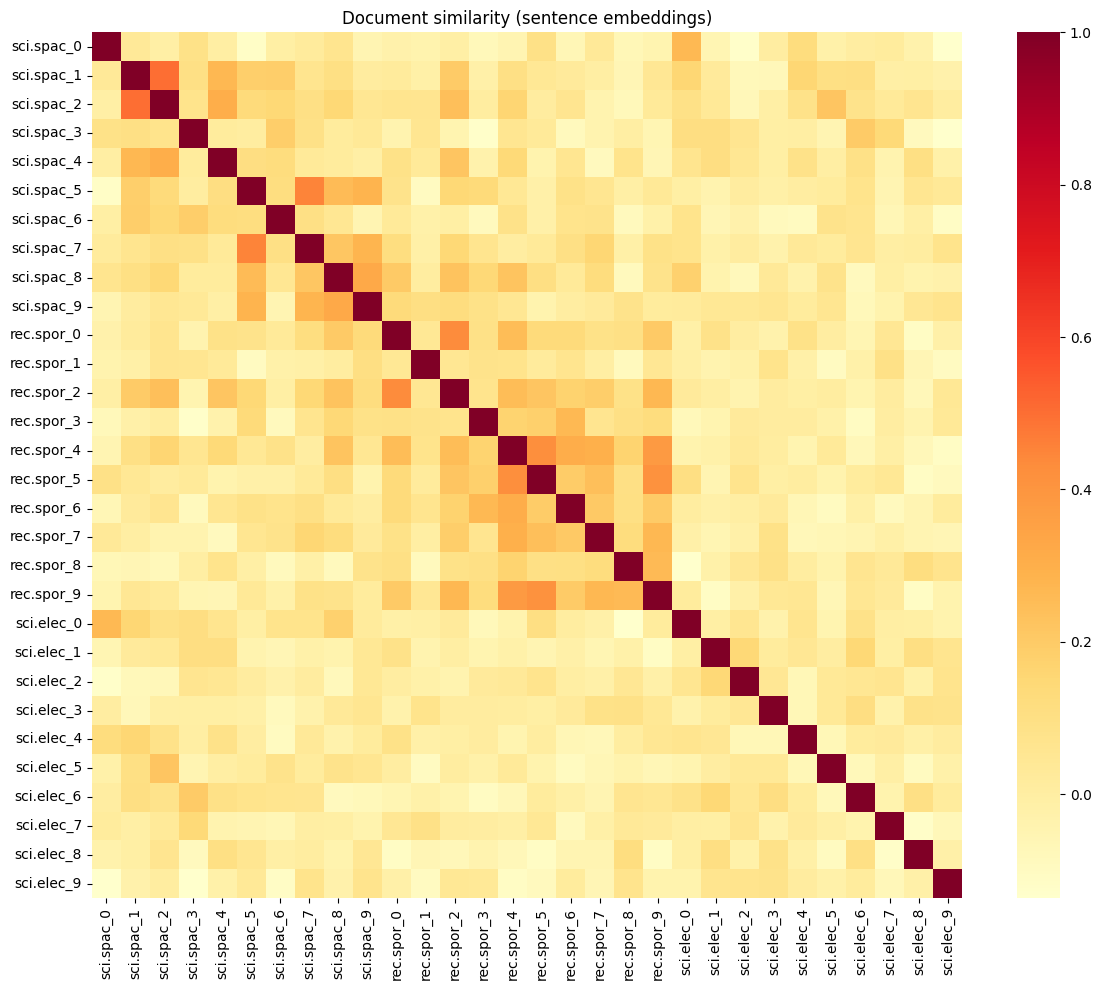

In [ ]:
df_sampled = pd.concat([
    df_filtered[df_filtered["label_text"] == c].sample(n=10, random_state=42)
    for c in my_categories
]).reset_index(drop=True)

sampled_docs = df_sampled["text"].str[:500].tolist()
sampled_labels = df_sampled["label_text"].tolist()

# YOUR CODE HERE
doc_embeddings = sentence_model.encode(sampled_docs)

bert_similarity = cosine_similarity(doc_embeddings)

assert doc_embeddings.shape == (30, 384) and bert_similarity.shape == (30, 30)

labels = [f"{l[:8]}_{i % 10}" for i, l in enumerate(sampled_labels)]

plt.figure(figsize=(12, 10))
sns.heatmap(
    bert_similarity,
    xticklabels=labels,
    yticklabels=labels,
    cmap="YlOrRd"
)

plt.title("Document similarity (sentence embeddings)")
plt.tight_layout()
plt.show()

### Question C.2 (written)

Compare with the TF-IDF heatmap of Lab 3.1 (same 30 documents):
1. Which representation groups documents of the same category better?
2. Are there documents judged similar by one method and not by the other? Why?
3. Which representation would you use for document classification? Why?

<!-- ANSWER lab3.2-C2 -->
1 TF-IDF groups documents of the same category more clearly because documents in each category share common keywords.

2 Yes. MiniLM may find documents similar even when they use different words because it understands meaning and context, while TF-IDF focuses on matching words.

3 I would choose TF-IDF for document classification because it is simple, fast and effective for identifying category-specific keywords.

### Exercise C.3 – Semantic search

In [ ]:
def semantic_search(query, documents, doc_embeddings, model, top_k=5):
    """Return the top_k (index, score) pairs of the documents closest to the query."""

    # 1. Encode the query
    query_embedding = model.encode([query])

    # 2. Calculate cosine similarity
    similarities = cosine_similarity(query_embedding, doc_embeddings)[0]

    # 3. Get the top 5 document indices
    top_indices = np.argsort(similarities)[::-1][:top_k]

    return [(int(i), float(similarities[i])) for i in top_indices]


# Query related to space science
my_query = "NASA space missions, rockets and satellite launches"

results = semantic_search(
    my_query, sampled_docs, doc_embeddings, sentence_model, top_k=5
)

assert len(results) == 5 and all(0 <= i < 30 for i, _ in results)

print(f"Query: '{my_query}'")
for idx, score in results:
    print(f"\n  score {score:.3f} | {sampled_labels[idx]}")
    print("  " + sampled_docs[idx][:150].replace("\n", " "))

Query: 'NASA space missions, rockets and satellite launches'

  score 0.389 | sci.space
   Lets hear it for Dan Goldin...now if he can only convince the rest of our federal government that the space program is a worth while investment!  I h

  score 0.346 | sci.space
  I am doing a political science paper on the funding of NASA and pork-barrel  politics.  I would be interested in information about funding practices a

  score 0.274 | sci.space
  From another space forum     When workers at the Kennedy Space Center disassembled the STS-56  solid rocket boosters they were surprised to find a pai

  score 0.100 | sci.space
   There was a recession, and none of the potential entrants could raise any money.  The race organizers were actually supposed to be handling part of t

  score 0.097 | sci.electronics
   I used a bunch as weights, when building a model airplane.  Hung them on the stringers, across the stringer, or whatever.  Worked pretty well.


In [ ]:
# Query related to two categories: space and electronics
my_query2 = "Electronic circuits, satellite communication and radio technology"

results2 = semantic_search(
    my_query2, sampled_docs, doc_embeddings, sentence_model, top_k=5
)

print(f"Query: '{my_query2}'")

for idx, score in results2:
    print(f"\nScore: {score:.3f} | {sampled_labels[idx]}")
    print(sampled_docs[idx][:150].replace("\n", " "))

Query: 'Electronic circuits, satellite communication and radio technology'

Score: 0.171 | sci.space
I am doing a political science paper on the funding of NASA and pork-barrel  politics.  I would be interested in information about funding practices a

Score: 0.166 | sci.electronics
 Not even in sub panels!  The only place the neutral should be connected to the ground is in a SERVICE DISCONNECT!  In your house the "main" panel ser

Score: 0.157 | sci.space
 Lets hear it for Dan Goldin...now if he can only convince the rest of our federal government that the space program is a worth while investment!  I h

Score: 0.145 | sci.electronics
 What you have is one of the LD players from a video game (Dragon's Lair, Space Ace, etc). Call Pioneer Technicial Support 213-498-0300 (at least that

Score: 0.143 | sci.space
    That would not explain why widely separated detectors, such as on Ulysses and PVO and Ginga et al., would see a burst at the same time(*).  In fac


### Question C.4 (written)

1. Are the results relevant to the query?
2. Do they come from the expected category?
3. Try a query that could match two of your categories: what happens?

<!-- ANSWER lab3.2-C4 -->
1 The search results were mostly relevant to my query about NASA, space missions and satellite launches. Most results came from the expected category, sci.space.


2 When I tried a query related to both space and electronics, the results included documents from both categories. This shows that MiniLM can understand semantic meaning and find related documents even when they do not contain exactly the same words.

---
# Part D – Visualizing embeddings with t-SNE

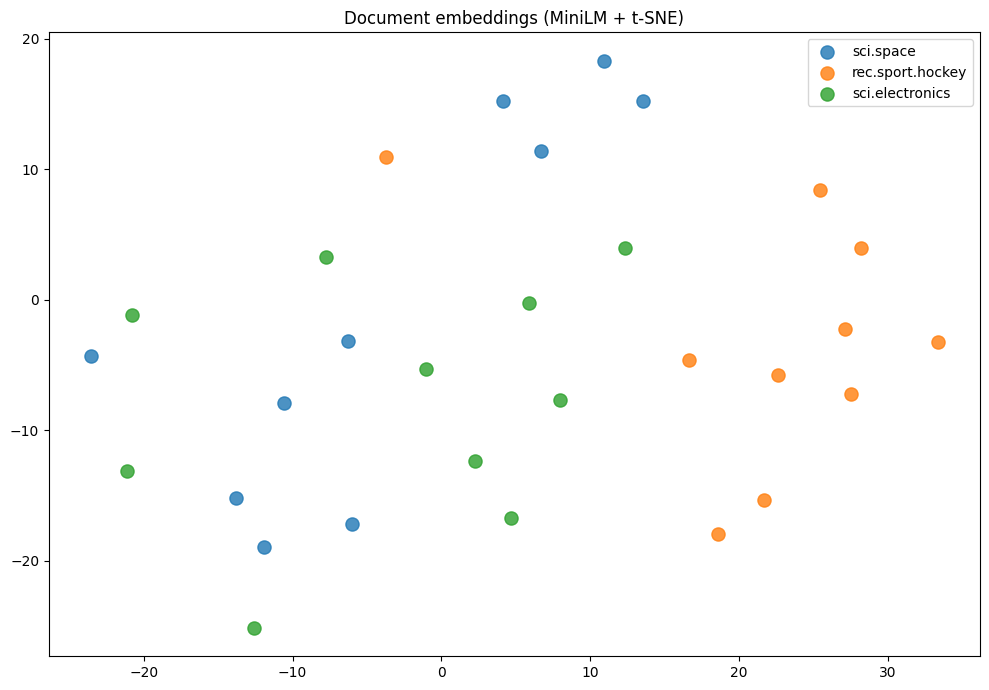

In [ ]:
from sklearn.manifold import TSNE

embeddings_2d = TSNE(n_components=2, random_state=42, perplexity=10).fit_transform(doc_embeddings)
plt.figure(figsize=(10, 7))
for category in my_categories:
    mask = np.array(sampled_labels) == category
    plt.scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1], label=category, s=90, alpha=0.8)
plt.legend()
plt.title("Document embeddings (MiniLM + t-SNE)")
plt.tight_layout()
plt.show()

### Question D.1 (written)

1. Do the categories form distinct clusters?
2. Are there documents in the "wrong" cluster? What could explain it?
3. Which two categories are the closest? Does it match Lab 3.1?

<!-- ANSWER lab3.2-D1 -->
**Your answer:**

1 The three categories form relatively distinct clusters in the t-SNE plot, although some documents overlap.

2 Some documents appear in the wrong clusters because they may discuss similar topics or share vocabulary with other categories.

3 The closest categories are sci.space and sci.electronics because both contain technical discussions. This matches Lab 3.1, where TF-IDF also showed higher similarity between these two categories.

---
# Part E – Final comparison

### Question E.1 (written)

1. Fill in the table.

| Method | Strengths | Weaknesses | Best use case |
|--------|-----------|------------|---------------|
| BoW | | |
| TF-IDF || |
| Word2Vec (own corpus) ||| |
| GloVe | | | |
| Sentence embeddings (MiniLM) ||||

2. For your categories, which method worked best overall? Support the answer with results from Labs 3.1 and 3.2.
3. For a real classification system on these categories, which representation would you choose and why?


Question E.1 – Comparison table

BoW

Strengths: Simple and easy to understand; counts word frequency.
Weaknesses: Does not understand meaning or context.
Best use case: Basic text analysis.
TF-IDF

Strengths: Highlights important and distinctive words.
Weaknesses: Cannot understand synonyms or semantic meaning.
Best use case: Document classification and keyword extraction.
Word2Vec (own corpus)

Strengths: Learns word relationships from our own data.
Weaknesses: Needs enough training data; may perform poorly on rare words.
Best use case: Domain-specific text analysis.
GloVe

Strengths: Pre-trained on a large corpus; has a broad vocabulary.
Weaknesses: May not understand specific domain vocabulary.
Best use case: General word similarity and analogies.
Sentence embeddings (MiniLM)

Strengths: Understands sentence meaning and context; useful for semantic search.
Weaknesses: Requires more computing power and resources.
Best use case: Semantic search and document similarity.

---
## Summary

- Word2Vec learns word vectors from your corpus; CBOW and Skip-gram differ in what they predict.
- Pre-trained vectors (GloVe) cover a large general vocabulary and support analogies.
- Sentence-transformer models embed whole texts and enable semantic search without shared words.
- t-SNE projects embeddings in 2-D to inspect how documents group together.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.